# Reto 3 · Modelo de clustering K-Means

**Clustering the Star — Mercedes-Benz · III Malackathon 2026**

Partimos de la matriz de features del Reto 2 (1 fila por cliente, 12 features escaladas) y:

1. Ejecutamos K-Means para **k = 2 … 10**
2. Calculamos el **método del codo** (inercia) y el **Silhouette Score** de cada k
3. Comprobamos que la segmentación no esté sesgada por **país** ni sea fruto de la **inicialización**
4. Entrenamos el **modelo final** con el k elegido y vemos la **distribución de clientes por cluster**

In [1]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, silhouette_samples, adjusted_rand_score

from features import cargar_datos, construir_pipeline, ajustar_kmeans, K_FINAL, SEMILLA, N_INIT_FINAL

sns.set_theme(style="whitegrid", palette="deep")
pd.set_option("display.float_format", "{:,.3f}".format)

df = cargar_datos()
pipe = construir_pipeline()
X = pipe.fit_transform(df)
clientes = pipe.named_steps["agregar"].transform(df)
pct_ch_total = (clientes["country_code"] == "CH").mean() * 100
print("Matriz:", X.shape, f"· clientes CH: {pct_ch_total:.1f} %")

Matriz: (173456, 12) · clientes CH: 66.2 %


## 1. Decisiones de método (y problemas que evitan)

| Riesgo | Qué pasaría | Cómo lo evitamos |
|---|---|---|
| Silhouette sobre 173.456 clientes | Coste O(n²): inviable en memoria y tiempo | Se calcula sobre **muestras aleatorias de 20.000 clientes**, repetido con 3 semillas; se reporta media y desviación |
| Inicialización aleatoria de K-Means | Resultados distintos en cada ejecución | Barrido de k con `n_init=10`; modelo final con `n_init=50` y `random_state` fijo. Se mide la estabilidad entre semillas (apartado 4) |
| Clusters que separan países | Segmentos que solo dicen "suizo / austriaco" | País fuera del modelo y poder adquisitivo + visitas al taller relativos al país (Reto 2). Se comprueba la mezcla de países por cluster |
| Clusters diminutos | Segmentos sin masa crítica para una campaña | Se vigila el tamaño del cluster más pequeño para cada k |
| Features con nulos estructurales | Clusters que separan "eléctrico / coche antiguo / no propietario" en vez de tipos de cliente | `tiene_telemetria` se retiró del modelo (Reto 1, apartado 3.3) |

In [2]:
SEMILLAS_SIL = [0, 1, 2]
TAM_MUESTRA = 20_000
resultados, modelos = [], {}
for k in range(2, 11):
    t = time.time()
    km = KMeans(n_clusters=k, n_init=10, random_state=SEMILLA).fit(X)
    sils = [silhouette_score(X, km.labels_, sample_size=TAM_MUESTRA, random_state=s) for s in SEMILLAS_SIL]
    tam = np.bincount(km.labels_) / len(X) * 100
    pct_ch = pd.crosstab(km.labels_, clientes["country_code"], normalize="index")["CH"] * 100
    resultados.append({"k": k, "inercia": km.inertia_, "silhouette": np.mean(sils), "silhouette_std": np.std(sils),
                       "cluster_min_%": tam.min(), "CH_min_%": pct_ch.min(), "CH_max_%": pct_ch.max(),
                       "segundos": time.time() - t})
    modelos[k] = km
res = pd.DataFrame(resultados).set_index("k")
res["caída_inercia_%"] = -res["inercia"].pct_change() * 100
res

,inercia,silhouette,silhouette_std,cluster_min_%,CH_min_%,CH_max_%,segundos,caída_inercia_%
k,,,,,,,,
2,"1,853,780.450",0.126,0.001,34.857,62.243,73.487,15.306,NaN
3,"1,689,401.128",0.145,0.000,16.461,54.576,69.489,13.086,8.867
4,"1,537,641.129",0.170,0.001,8.882,54.544,70.033,16.585,8.983
5,"1,424,611.268",0.132,0.000,8.821,54.496,73.460,11.138,7.351
6,"1,341,133.438",0.135,0.000,8.752,54.905,74.147,11.297,5.860
7,"1,267,222.851",0.137,0.000,7.735,54.744,85.548,11.077,5.511
8,"1,210,867.016",0.138,0.000,7.072,54.771,85.564,11.291,4.447
9,"1,177,967.527",0.126,0.001,5.065,55.002,85.462,12.064,2.717
10,"1,141,215.278",0.122,0.001,3.559,55.195,85.860,12.108,3.120


## 2. Método del codo y Silhouette

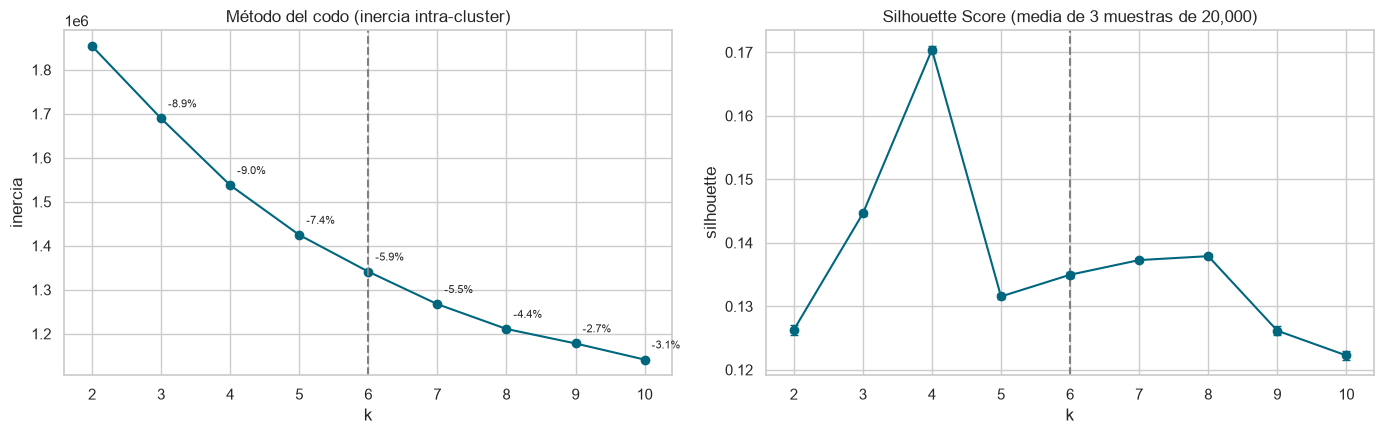

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
axes[0].plot(res.index, res["inercia"], "o-", color="#00677F")
axes[0].axvline(K_FINAL, ls="--", color="grey")
for k, v in res["caída_inercia_%"].dropna().items():
    axes[0].annotate(f"-{v:.1f}%", (k, res.loc[k, "inercia"]), textcoords="offset points", xytext=(5, 8), fontsize=8)
axes[0].set(title="Método del codo (inercia intra-cluster)", xlabel="k", ylabel="inercia")
axes[1].errorbar(res.index, res["silhouette"], yerr=res["silhouette_std"], fmt="o-", color="#00677F", capsize=3)
axes[1].axvline(K_FINAL, ls="--", color="grey")
axes[1].set(title=f"Silhouette Score (media de {len(SEMILLAS_SIL)} muestras de {TAM_MUESTRA:,})", xlabel="k", ylabel="silhouette")
plt.tight_layout()
plt.show()

**Lectura:**
- **Codo**: la inercia baja de forma suave, sin un codo nítido. La mayor caída relativa es al pasar a k = 4 (9,0 %, casi igual que a k = 3);
  después cada cluster extra aporta cada vez menos (7,3 % → 5,9 % → 5,5 % → 4,4 %) y a partir de k = 9 la mejora es
  marginal (< 3,5 %). El codo está en la zona **k = 4-6**.
- **Silhouette**: el máximo está en **k = 4 (0,170)**. Entre k = 5 y k = 8 hay una meseta (0,132-0,138) y a partir de
  k = 9 cae. La desviación entre muestras es mínima (≤ 0,001), así que el muestreo no distorsiona la métrica.
- **¿Es bajo un silhouette de 0,13-0,17?** Sí, y es esperable: los clientes no forman grupos naturalmente separados,
  sino un **continuo** (edad, antigüedad, gama…). K-Means "corta" ese continuo en zonas homogéneas. Lo importante
  es que los segmentos sean **distintos, estables y accionables**, que es lo que se comprueba a continuación.

## 3. ¿Algún cluster es "un país"?

Si la segmentación estuviera sesgada por país, algún cluster tendría casi todo suizos o casi todo austriacos.
Referencia: el 66 % de los clientes son suizos.

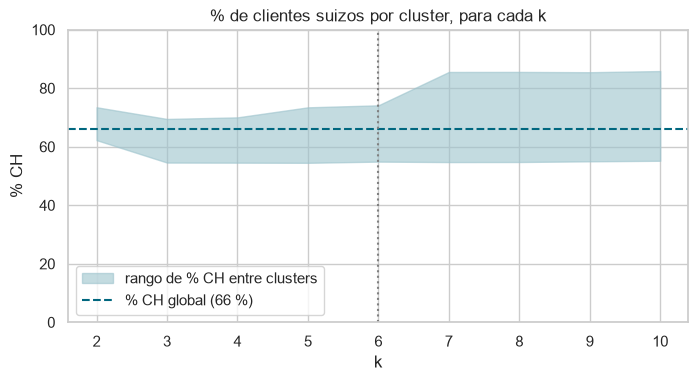

In [4]:
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.fill_between(res.index, res["CH_min_%"], res["CH_max_%"], color="#9cc3cc", alpha=.6, label="rango de % CH entre clusters")
ax.axhline(pct_ch_total, color="#00677F", ls="--", label=f"% CH global ({pct_ch_total:.0f} %)")
ax.axvline(K_FINAL, ls=":", color="grey")
ax.set(title="% de clientes suizos por cluster, para cada k", xlabel="k", ylabel="% CH", ylim=(0, 100))
ax.legend(loc="lower left")
plt.show()

Hasta **k = 6** todos los clusters tienen entre un ~55 % y un ~74 % de clientes suizos: **ningún segmento es un
país**. A partir de k = 7 aparece un cluster de **leasing activo** con un ~86 % de suizos. No es un error de datos:
el leasing está mucho más extendido en Suiza (29 % de clientes frente a 13 % en Austria), y se decidió mantenerlo
como comportamiento real. Aun así, es otro motivo para no ir más allá de k = 6.

**Problemas detectados y corregidos durante este reto:**
1. En una primera versión, las visitas al taller se usaban en valor absoluto y generaban un cluster con un 81-86 % de
   suizos. El motivo era una diferencia de **registro** entre países (52 % de austriacos con 0 visitas frente a 23 % de
   suizos, con coches de antigüedad similar). Se corrigió en el Reto 2 expresando las visitas como percentil dentro del país.
2. La primera versión incluía `tiene_telemetria`. La auditoría de nulos del Reto 1 mostró que su ausencia es
   **estructural** (eléctricos, roles no propietarios, coches antiguos), así que se retiró del modelo. Los 6 segmentos
   finales son prácticamente los mismos con y sin ella: la segmentación **no dependía** de esa variable sesgada.

## 4. Elección de k

Las métricas señalan k = 4 como óptimo. Antes de aceptarlo, se mira **qué segmentos produce**.

In [5]:
comparativa = {}
for k in [4, 5, 6]:
    tam = pd.Series(modelos[k].labels_).value_counts(normalize=True).mul(100)
    comparativa[k] = {"silhouette": res.loc[k, "silhouette"], "cluster más grande (%)": tam.max(),
                      "cluster más pequeño (%)": tam.min(), "% CH máx. en un cluster": res.loc[k, "CH_max_%"]}
pd.DataFrame(comparativa).round(3)

,4,5,6
silhouette,0.170,0.132,0.135
cluster más grande (%),56.560,30.694,27.029
cluster más pequeño (%),8.882,8.821,8.752
% CH máx. en un cluster,70.033,73.460,74.147


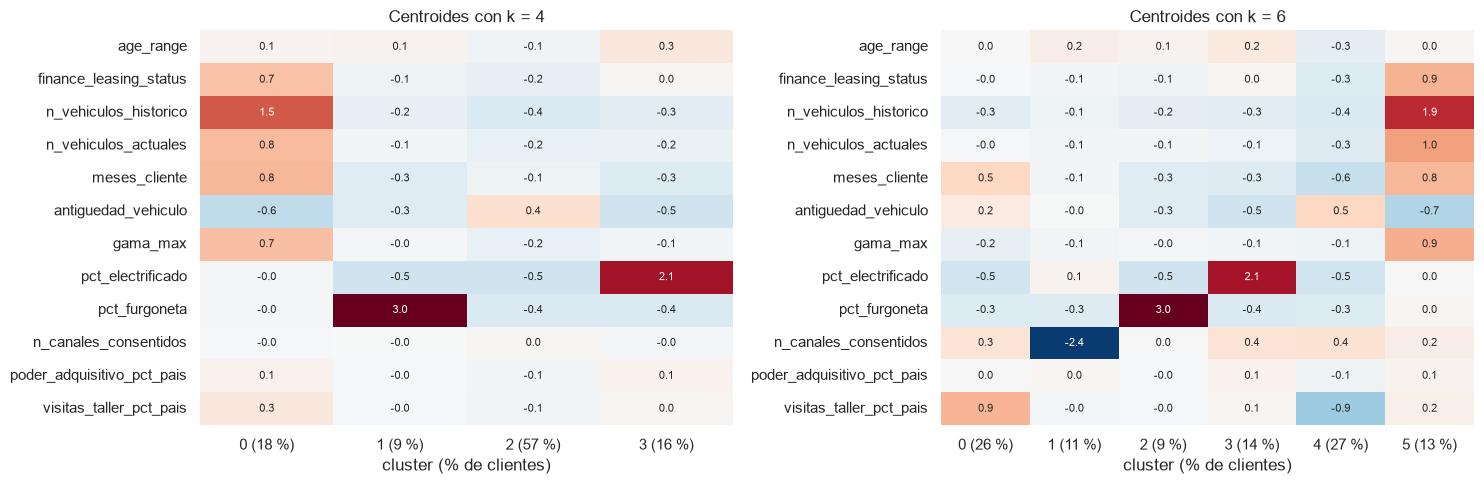

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
for ax, k in zip(axes, [4, 6]):
    cen = pd.DataFrame(modelos[k].cluster_centers_, columns=X.columns)
    cen.index = [f"{i} ({p:.0f} %)" for i, p in enumerate(np.bincount(modelos[k].labels_) / len(X) * 100)]
    sns.heatmap(cen.T, cmap="RdBu_r", center=0, vmin=-2.5, vmax=2.5, annot=True, fmt=".1f", ax=ax, cbar=False, annot_kws={"size": 8})
    ax.set(title=f"Centroides con k = {k}", xlabel="cluster (% de clientes)")
plt.tight_layout()
plt.show()

Con **k = 4**, K-Means separa tres grupos muy marcados (multi-vehículo, electrificados y furgonetas) y deja al
**57 % de los clientes en un único cluster genérico**. El silhouette es mayor justamente porque los tres grupos
pequeños están muy separados, pero más de la mitad de la base queda sin segmentar. Para marketing, eso equivale a
"todos los demás".

Con **k = 6**, ese bloque se divide en tres grupos con un uso comercial directo:
- **clientes recientes y con poco taller** (poca antigüedad como cliente, coche más antiguo, pocas visitas):
  candidatos a fidelización;
- **clientes fieles al taller** (muchas visitas, años de relación): el público natural de los planes de mantenimiento;
- **clientes con pocos consentimientos**: necesitan recaptar permisos antes de cualquier campaña.

| Criterio | k = 4 | k = 6 |
|---|---|---|
| Silhouette | **0,170** | 0,135 (meseta de 5-8) |
| Codo | Mayor caída de inercia | Las caídas siguen siendo apreciables (5,9 %) |
| Mezcla de países | OK | OK |
| Cluster más grande | 57 % | 27 % |
| Accionabilidad | 3 segmentos claros + 1 bloque genérico | 6 segmentos con estrategia propia |

**Elegimos k = 6**: se sacrifica algo de silhouette (sigue en la meseta de 5-8) a cambio de segmentar a toda la base
en grupos útiles. Con k ≥ 7 el silhouette no mejora, aparece un cluster dominado por un país y la segmentación se
vuelve difícil de gestionar.

### Estabilidad frente a la inicialización

K-Means parte de centroides aleatorios y puede quedarse en un **óptimo local**. Entrenamos k = 6 con 5 semillas y
comparamos las asignaciones con el **Adjusted Rand Index** (1 = mismas asignaciones salvo el nombre del cluster).
Primero con `n_init=10`, el valor por defecto razonable.

In [7]:
SEMILLAS = [42, 0, 1, 2, 3]
def estabilidad(n_init):
    fits = {sd: KMeans(n_clusters=K_FINAL, n_init=n_init, random_state=sd).fit(X) for sd in SEMILLAS}
    ari = pd.DataFrame({a: {b: adjusted_rand_score(fits[a].labels_, fits[b].labels_) for b in fits} for a in fits})
    inercias = pd.Series({sd: f.inertia_ for sd, f in fits.items()}, name="inercia")
    return ari, inercias, fits

ari10, inercias10, fits10 = estabilidad(10)
print(f"n_init=10 · ARI medio entre semillas: {ari10.values[np.triu_indices(5, 1)].mean():.3f}")
display(ari10.round(3))
inercias10.round(0).to_frame()

n_init=10 · ARI medio entre semillas: 0.996


,42,0,1,2,3
42,1.000,0.995,0.999,0.996,0.995
0,0.995,1.000,0.994,0.998,0.998
1,0.999,0.994,1.000,0.995,0.995
2,0.996,0.998,0.995,1.000,0.999
3,0.995,0.998,0.995,0.999,1.000


,inercia
42,"1,341,133.000"
0,"1,341,131.000"
1,"1,341,135.000"
2,"1,341,131.000"
3,"1,341,132.000"


**Resultado:** con `n_init=10` las 5 semillas llegan prácticamente a la misma solución (ARI medio ≈ 0,996; las
inercias difieren en unas pocas unidades sobre 1,34 millones).

**No siempre fue así.** Con la versión anterior del pipeline, que usaba el poder adquisitivo **por hogar** (Reto 1,
apartado 6.2), `n_init=10` daba **dos soluciones distintas** según la semilla (ARI ≈ 0,61 entre ellas): una cambiaba
el segmento de "pocos consentimientos" por uno de "leasing". Es decir, otro miembro del equipo podía obtener segmentos
diferentes con el mismo código. Con el poder adquisitivo por habitante ese problema desaparece, pero demuestra que la
estabilidad **depende de los datos**.

**Decisión:** se mantiene `n_init=50` (50 inicializaciones, se queda con la de menor inercia). Cuesta unos segundos y
protege frente a ese riesgo si los datos cambian.

In [8]:
ari50, inercias50, fits50 = estabilidad(N_INIT_FINAL)
print(f"n_init={N_INIT_FINAL} · ARI medio entre semillas: {ari50.values[np.triu_indices(5, 1)].mean():.3f}")
display(ari50.round(3))
pd.DataFrame({"inercia n_init=10": inercias10, f"inercia n_init={N_INIT_FINAL}": inercias50}).round(0)

n_init=50 · ARI medio entre semillas: 0.997


,42,0,1,2,3
42,1.000,0.999,0.995,0.998,0.998
0,0.999,1.000,0.995,0.998,0.998
1,0.995,0.995,1.000,0.997,0.996
2,0.998,0.998,0.997,1.000,0.999
3,0.998,0.998,0.996,0.999,1.000


,inercia n_init=10,inercia n_init=50
42,"1,341,133.000","1,341,131.000"
0,"1,341,131.000","1,341,131.000"
1,"1,341,135.000","1,341,133.000"
2,"1,341,131.000","1,341,131.000"
3,"1,341,132.000","1,341,132.000"


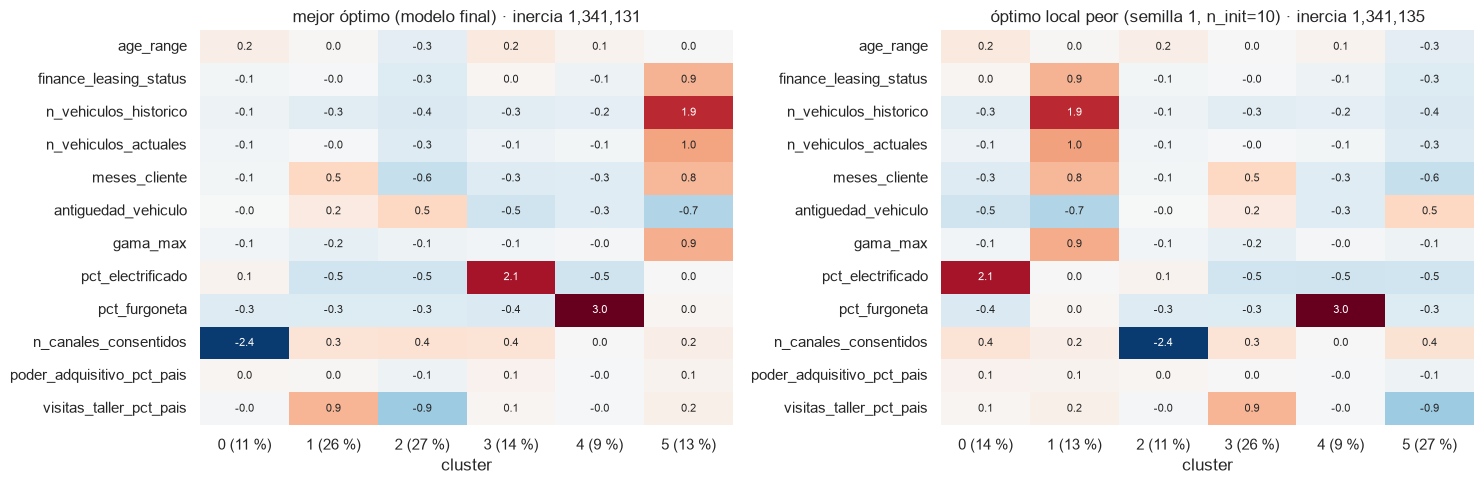

In [9]:
# Comprobación visual: la ejecución de n_init=10 con más inercia frente al modelo final
peor = inercias10.idxmax()
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
for ax, (titulo, km_) in zip(axes, [("mejor óptimo (modelo final)", fits50[SEMILLA]), (f"óptimo local peor (semilla {peor}, n_init=10)", fits10[peor])]):
    cen = pd.DataFrame(km_.cluster_centers_, columns=X.columns)
    cen.index = [f"{i} ({p:.0f} %)" for i, p in enumerate(np.bincount(km_.labels_) / len(X) * 100)]
    sns.heatmap(cen.T, cmap="RdBu_r", center=0, vmin=-2.5, vmax=2.5, annot=True, fmt=".1f", ax=ax, cbar=False, annot_kws={"size": 8})
    ax.set(title=f"{titulo} · inercia {km_.inertia_:,.0f}", xlabel="cluster")
plt.tight_layout()
plt.show()

Los centroides de la peor ejecución con `n_init=10` y del modelo final son prácticamente iguales. Con 50
inicializaciones todas las semillas convergen a la **misma solución**, la de menor inercia. El modelo final se entrena
así (`ajustar_kmeans` en `features.py`), de modo que el Reto 4 y cualquier miembro del equipo
obtienen exactamente los mismos segmentos.

## 5. Modelo final (k = 6) y distribución de clientes

In [10]:
km = ajustar_kmeans(X)
clientes["cluster"] = km.labels_
dist = clientes["cluster"].value_counts().sort_index().to_frame("clientes")
dist["%"] = dist["clientes"] / len(clientes) * 100
dist

,clientes,%
cluster,,
0,18846,10.865
1,45449,26.202
2,46920,27.050
3,24754,14.271
4,15183,8.753
5,22304,12.859


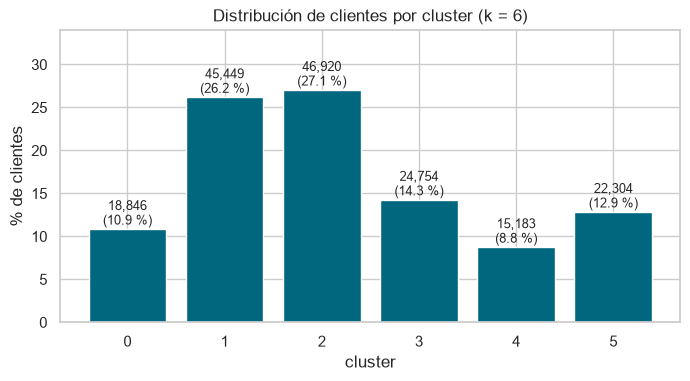

In [11]:
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.bar(dist.index.astype(str), dist["%"], color="#00677F")
for i, (n, p) in enumerate(zip(dist["clientes"], dist["%"])):
    ax.text(i, p + 0.5, f"{n:,}\n({p:.1f} %)", ha="center", fontsize=9)
ax.set(title="Distribución de clientes por cluster (k = 6)", xlabel="cluster", ylabel="% de clientes", ylim=(0, dist["%"].max() + 7))
plt.show()

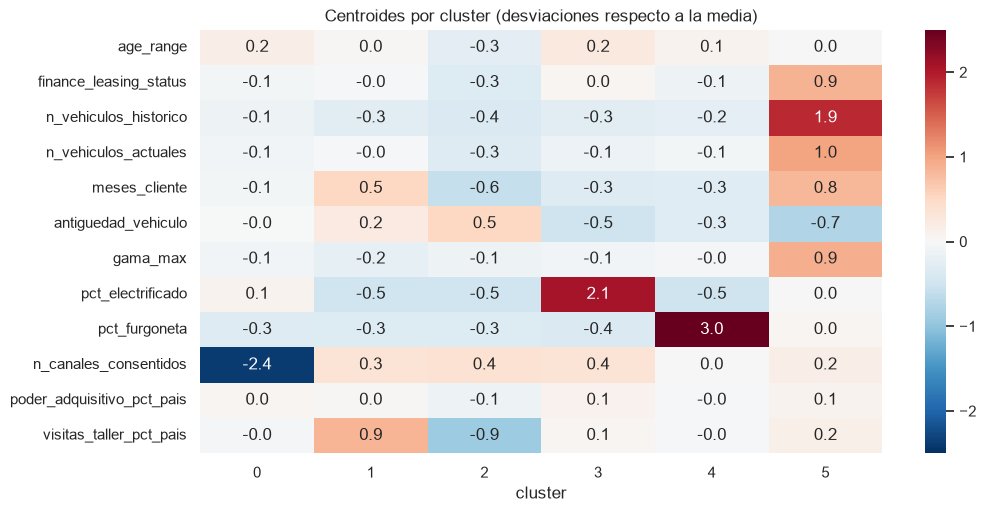

In [12]:
# Centroides en unidades estandarizadas: qué distingue a cada cluster
centroides = pd.DataFrame(km.cluster_centers_, columns=X.columns)
plt.figure(figsize=(11, 5.5))
sns.heatmap(centroides.T, cmap="RdBu_r", center=0, vmin=-2.5, vmax=2.5, annot=True, fmt=".1f")
plt.title("Centroides por cluster (desviaciones respecto a la media)")
plt.xlabel("cluster")
plt.show()

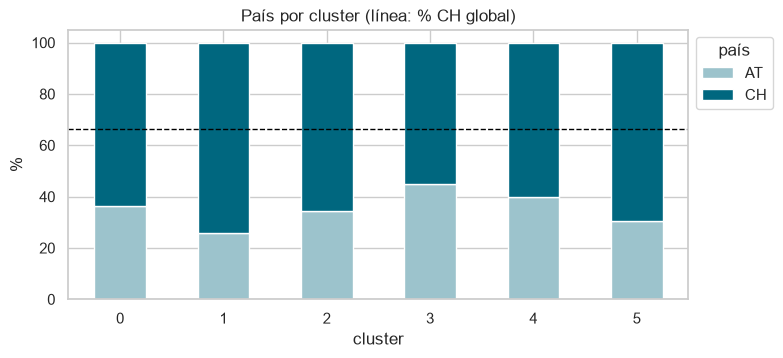

In [13]:
# Mezcla de países en el modelo final
mezcla = pd.crosstab(clientes["cluster"], clientes["country_code"], normalize="index").mul(100)
mezcla.plot.bar(stacked=True, figsize=(8, 3.5), color=["#9cc3cc", "#00677F"], rot=0)
plt.axhline(pct_ch_total, color="black", ls="--", lw=1)
plt.title("País por cluster (línea: % CH global)")
plt.ylabel("%")
plt.legend(title="país", bbox_to_anchor=(1, 1))
plt.show()

### Silhouette por cluster

Un silhouette medio bajo puede esconder clusters bien definidos y otros difusos. Lo calculamos por cluster
sobre una muestra.

In [14]:
muestra = np.random.default_rng(0).choice(len(X), TAM_MUESTRA, replace=False)
sil_ind = silhouette_samples(X.iloc[muestra], km.labels_[muestra])
sil_cluster = pd.Series(sil_ind).groupby(km.labels_[muestra]).agg(["mean", lambda s: (s < 0).mean() * 100])
sil_cluster.columns = ["silhouette medio", "% clientes con silhouette < 0"]
sil_cluster

,silhouette medio,% clientes con silhouette < 0
0,0.084,10.112
1,0.163,0.000
2,0.122,6.146
3,0.171,1.086
4,0.227,0.948
5,0.048,39.797


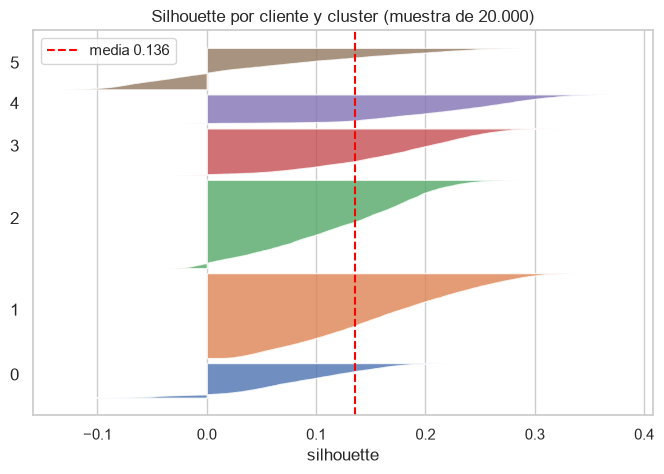

In [15]:
fig, ax = plt.subplots(figsize=(8, 5))
y = 0
for c in range(K_FINAL):
    v = np.sort(sil_ind[km.labels_[muestra] == c])
    ax.fill_betweenx(np.arange(y, y + len(v)), 0, v, alpha=.8)
    ax.text(-0.18, y + len(v) / 2, str(c))
    y += len(v) + 300
ax.axvline(sil_ind.mean(), color="red", ls="--", label=f"media {sil_ind.mean():.3f}")
ax.set(title="Silhouette por cliente y cluster (muestra de 20.000)", xlabel="silhouette", yticks=[])
ax.legend()
plt.show()

**Lectura por cluster:** los grupos definidos por un rasgo muy marcado (furgonetas, electrificados, fieles al taller)
son los más compactos. El grupo **multi-vehículo / leasing / gama alta** es el más difuso: muchos de sus clientes
tienen silhouette negativo, es decir, están en la frontera con otros clusters. Agrupa perfiles de alto valor pero
heterogéneos (desde familias con dos coches hasta pequeñas flotas). En el Reto 4 se perfila con cuidado y se
recomienda **sub-segmentarlo** si se quiere afinar una campaña sobre él.

## 6. Conclusiones

- Se evaluó K-Means para k = 2 … 10 con codo y silhouette. Las métricas apuntan a k = 4, pero deja al 57 % de los
  clientes en un bloque genérico. Se eligió **k = 6**: silhouette en la meseta de 5-8 (0,135) y toda la base
  repartida en segmentos accionables.
- Los 6 clusters tienen masa crítica (el más pequeño ≈ 9 % de los clientes, más de 15.000) y **ninguno está
  dominado por un país**.
- **Estabilidad**: todas las semillas convergen a la misma solución (ARI ≈ 0,997 con `n_init=50`). Con el poder
  adquisitivo por hogar, `n_init=10` caía a veces en un óptimo local peor; se mantiene `n_init=50` como protección.
- El cluster multi-vehículo / leasing / gama alta es el menos cohesionado (silhouette ≈ 0,05): segmento de alto
  valor pero heterogéneo.
- Problemas detectados y resueltos: coste del silhouette (muestreo repetido), sesgo de registro de las visitas
  al taller entre países (percentil por país), nulo estructural de la telemetría (retirada del modelo) y riesgo de
  clusters "país" con k ≥ 7 (se descarta).
- En el Reto 4 se interpreta cada cluster en lenguaje de negocio y se le pone nombre.